# Quantum portfolio selection: penalty vs constraint-native QAOA on rolling Euro Stoxx 50 windows

**Research question.** For cardinality-constrained mean–variance selection (choose exactly *k* of *n* assets), does a constraint-native QAOA (ring XY mixer, Dicke or basis start) give better solution quality than penalty QAOA (transverse mixer + quadratic penalty), measured across 140 real monthly instances (Jan 2015 – Aug 2026)? Secondary: do parameters transfer from one month to the next, and what does the out-of-sample portfolio do (descriptively, not as a trading claim)?

Scope and honesty notes
* Exact noiseless statevector simulation; no hardware claims. QAOA universe: 12 stocks (≥1 per main sector), k = 4 → 4096 states, 495 feasible. Classical exact optimum by enumeration for every month.
* Data: Yahoo Finance adjusted month-end closes (dividends reinvested), downloaded by the user with the scripts in this repo; **raw data are not redistributed**. Benchmark: Curvo Euro Stoxx 50 backtest series (EUR). Whether it is total return must be checked; see the note in §6.
* Survivorship bias: the universe is today's index members, so any backtest is optimistic. **Not investment advice.**
* Seeded: every random number comes from `SEED`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time, json, os
from scipy.optimize import minimize
from scipy.stats import wilcoxon
from itertools import combinations
SEED=20261012; rng0=np.random.default_rng(SEED)
DATA='data'; OUT='results'; os.makedirs(OUT,exist_ok=True)
QAOA_TICKERS=['ASML.AS','SAP.DE','SIE.DE','AIR.PA','SAN.MC','ALV.DE','TTE.PA','IBE.MC','MC.PA','OR.PA','SAN.PA','DTE.DE']
K=4; WIN=12; Q_RISK=2.0; P_LAYERS=2; RESTARTS=5; SHOTS=100
uni=pd.read_csv('universe.csv').set_index('ticker')
px=pd.read_csv(f'{DATA}/prices_monthly.csv',index_col=0,parse_dates=True)
assert px.isna().sum().sum()==0 and len(px)==152
R=px.pct_change().dropna()          # simple monthly returns
L=np.log(px).diff().dropna()       # log returns for estimation
print(px.index[0].date(), px.index[-1].date(), R.shape)
uni.loc[QAOA_TICKERS,['name','sector']]

2014-01-31 2026-08-31 (151, 20)


,name,sector
ticker,,
ASML.AS,ASML Holding,Information Technology
SAP.DE,SAP,Information Technology
SIE.DE,Siemens,Industrials
AIR.PA,Airbus,Industrials
SAN.MC,Banco Santander,Financials
ALV.DE,Allianz,Financials
TTE.PA,TotalEnergies,Energy
IBE.MC,Iberdrola,Utilities
MC.PA,LVMH,Consumer Discretionary


## 1. Monthly instances
For each rebalance month *t* (Jan 2015 … Aug 2026) we estimate annualised μ and Σ from the previous 12 monthly log returns only (no look-ahead) and define

maximise f(x) = μᵀx − q·xᵀΣx, subject to Σᵢxᵢ = k, x ∈ {0,1}ⁿ, with q = 2.

The objective is a QUBO exactly (no approximation); only the constraint has to be handled, by penalty or by the mixer.

In [2]:
n=len(QAOA_TICKERS); N=2**n
bits=((np.arange(N)[:,None]>>np.arange(n))&1).astype(float)   # bit i = asset i
ham=bits.sum(1); FEAS=ham==K
months=[d for d in L.index if (L.index<d).sum()>=WIN and d>=pd.Timestamp('2015-01-01')]
def instance(t):
    h=L.loc[L.index<t, QAOA_TICKERS].iloc[-WIN:]
    mu=h.mean().values*12; S=h.cov().values*12
    f=bits@mu - Q_RISK*np.einsum('si,ij,sj->s',bits,S,bits)
    return mu,S,f
inst={t:instance(t) for t in months}
print(len(months),'instances;', months[0].date(),'->',months[-1].date())

139 instances; 2015-02-28 -> 2026-08-31


## 2. Simulator and the four methods
* `pen_auto`: |+⟩ⁿ, transverse mixer, penalty P_auto = 1 + Σ|QUBO coeffs| (the conservative bound qiskit-optimization uses).
* `pen_tight`: same, P_tight = largest one-flip gain of the scaled objective (+ margin): just enough so that no infeasible state beats the optimum by moving the Hamming weight by one. Heuristic, documented.
* `xy_basis`: start |1111 0…0⟩, ring XY mixer (odd/even edge layers). Hamming weight is conserved exactly.
* `xy_dicke`: Dicke state |D(12,4)⟩, same mixer.

The cost is rescaled per month to c ∈ [0,1] over the feasible set (0 = optimum) so that one γ range works every month. All methods: p = 2, 5 random restarts, L-BFGS-B, same budget.

In [3]:
def apply_rx(psi,beta):
    c,s=np.cos(beta),-1j*np.sin(beta)
    for q in range(n):
        v=psi.reshape(-1,2,2**q); a=v[:,0,:].copy(); b=v[:,1,:]
        v[:,0,:]=c*a+s*b; v[:,1,:]=s*a+c*b
    return psi
ring=[(i,(i+1)%n) for i in range(n)]
def pairs(edges):
    out=[]
    for a,b in edges:
        idx=np.where(((np.arange(N)>>a)&1==1)&((np.arange(N)>>b)&1==0))[0]
        out.append((idx, idx^((1<<a)|(1<<b))))
    return out
XY_LAYERS=[pairs(ring[0::2]),pairs(ring[1::2])]
def apply_xy(psi,beta):
    c,s=np.cos(beta),-1j*np.sin(beta)
    for layer in XY_LAYERS:
        for i,j in layer:
            a=psi[i].copy(); b=psi[j]; psi[i]=c*a+s*b; psi[j]=s*a+c*b
    return psi
plus=np.full(N,1/np.sqrt(N),complex)
dicke=FEAS/np.sqrt(FEAS.sum())+0j
basis=np.zeros(N,complex); basis[int('1'*K,2)]=1
def scaled_cost(f):
    fe=f[FEAS]; c=(fe.max()-f)/(fe.max()-fe.min())   # 0 = best feasible
    return c
def penalties(c):
    # one-flip gain bound for c restricted near the feasible set
    gain=np.abs(c[:,None]-c[np.arange(N)[:,None]^(1<<np.arange(n))]).max()
    return {'pen_auto':1+np.abs(c).sum()/N*n*n, 'pen_tight':gain+0.1}
def run(method,c,theta0=None,restarts=RESTARTS,seed=0):
    rng=np.random.default_rng(seed)
    if method.startswith('pen'):
        P=penalties(c)[method]; H=c+P*(ham-K)**2; start,mix=plus,apply_rx
    else:
        H=c.copy(); start=dicke if method=='xy_dicke' else basis; mix=apply_xy
    def state(th):
        psi=start.copy()
        for l in range(P_LAYERS):
            psi=psi*np.exp(-1j*th[l]*H); psi=mix(psi,th[P_LAYERS+l])
        return psi
    def E(th): return float(np.abs(state(th))**2@H)
    starts=[theta0] if theta0 is not None else [np.r_[rng.uniform(0,2*np.pi,P_LAYERS),rng.uniform(0,np.pi,P_LAYERS)] for _ in range(restarts)]
    best=None; nfev=0
    for x0 in starts:
        r=minimize(E,x0,method='L-BFGS-B',options={'maxiter':200}); nfev+=r.nfev
        if best is None or r.fun<best.fun: best=r
    pr=np.abs(state(best.x))**2
    return best.x,pr,nfev
def metrics(pr,c):
    pf=pr[FEAS].sum(); cf=c[FEAS]
    opt=FEAS&(c<=1e-12)
    ratio=1-(pr[FEAS]@cf)/pf if pf>1e-12 else np.nan
    return dict(p_feas=pf,p_opt=pr[opt].sum(),ratio_cond=ratio,ratio_uncond=1-(pr*np.where(FEAS,c,1)).sum())
METHODS=['pen_auto','pen_tight','xy_basis','xy_dicke']

## 3. Run all 140 months × 4 methods

In [4]:
rows=[]; thetas={}; samples={}; t0=time.time()
for mi,t in enumerate(months):
    c=scaled_cost(inst[t][2]); c_full=np.where(FEAS,c,np.nan)
    for m in METHODS:
        th,pr,nf=run(m,c,seed=SEED+mi)
        rs=np.random.default_rng(SEED+7*mi).choice(N,SHOTS,p=pr/pr.sum())
        fe=rs[FEAS[rs]]
        best=fe[np.argmin(c[fe])] if len(fe) else -1
        rows.append(dict(month=t,method=m,nfev=nf,best_shot_opt=(best>=0 and c[best]<=1e-12),best_idx=best,**metrics(pr,c)))
        thetas[(t,m)]=th
    # uniform-feasible random baseline
    rows.append(dict(month=t,method='random_feasible',ratio_cond=1-c[FEAS].mean(),p_opt=1/FEAS.sum(),p_feas=FEAS.mean()))
res=pd.DataFrame(rows); res.to_csv(f'{OUT}/qaoa_monthly.csv',index=False)
print(f'{time.time()-t0:.0f}s')

396s


## 4. Statistics (bootstrap 95% CI of the mean over months; paired Wilcoxon vs `xy_dicke`)

In [5]:
def boot(x,B=5000,seed=SEED):
    x=np.asarray(x,float); x=x[~np.isnan(x)]; r=np.random.default_rng(seed)
    m=r.choice(x,(B,len(x))).mean(1); return x.mean(),*np.percentile(m,[2.5,97.5])
tab=[]
for m in METHODS+['random_feasible']:
    d=res[res.method==m]
    row={'method':m}
    for k_ in ['ratio_cond','p_opt','p_feas']:
        mu,lo,hi=boot(d[k_]); row[k_]=f'{mu:.3f} [{lo:.3f}, {hi:.3f}]'
    if m in METHODS: row['best_of_100_finds_opt']=f"{d.best_shot_opt.astype(float).mean():.2f}"; row['mean_nfev']=int(d.nfev.mean())
    tab.append(row)
summary=pd.DataFrame(tab).set_index('method'); summary.to_csv(f'{OUT}/summary.csv'); display(summary)
piv=res.pivot(index='month',columns='method',values='p_opt')
for m in ['pen_auto','pen_tight','xy_basis']:
    d=piv['xy_dicke']-piv[m]; s=wilcoxon(d)
    print(f'p_opt  xy_dicke - {m:9s}: mean {d.mean():+.3f}, CI {boot(d)[1]:+.3f}..{boot(d)[2]:+.3f}, Wilcoxon p={s.pvalue:.1e}, dicke better in {(d>0).mean():.0%} of months')

,ratio_cond,p_opt,p_feas,best_of_100_finds_opt,mean_nfev
method,,,,,
pen_auto,"0.599 [0.573, 0.625]","0.006 [0.004, 0.008]","0.552 [0.536, 0.568]",0.29,1653.0
pen_tight,"0.647 [0.622, 0.670]","0.011 [0.008, 0.014]","0.501 [0.477, 0.524]",0.42,734.0
xy_basis,"0.682 [0.660, 0.705]","0.007 [0.000, 0.022]","1.000 [1.000, 1.000]",0.01,301.0
xy_dicke,"0.776 [0.770, 0.783]","0.035 [0.030, 0.041]","1.000 [1.000, 1.000]",0.82,899.0
random_feasible,"0.561 [0.552, 0.569]","0.002 [0.002, 0.002]","0.121 [0.121, 0.121]",NaN,NaN


p_opt  xy_dicke - pen_auto : mean +0.029, CI +0.024..+0.035, Wilcoxon p=6.6e-21, dicke better in 91% of months
p_opt  xy_dicke - pen_tight: mean +0.024, CI +0.018..+0.030, Wilcoxon p=6.3e-15, dicke better in 85% of months
p_opt  xy_dicke - xy_basis : mean +0.028, CI +0.010..+0.039, Wilcoxon p=2.9e-23, dicke better in 99% of months


## 5. Parameter transfer across months
For `xy_dicke`: (A) fresh, 5 random restarts (from §3) vs (B) a single start from the previous month's optimum θ, vs (C) last month's θ used **without** re-optimisation. If B ≈ A at ~1/5 the cost and C is close, parameters concentrate across market regimes.

In [6]:
tr=[]
for mi,t in enumerate(months[1:],1):
    c=scaled_cost(inst[t][2]); prev=thetas[(months[mi-1],'xy_dicke')]
    _,prB,nfB=run('xy_dicke',c,theta0=prev)
    # C: no optimisation
    H=c; psi=dicke.copy()
    for l in range(P_LAYERS): psi=apply_xy(psi*np.exp(-1j*prev[l]*H),prev[P_LAYERS+l])
    prC=np.abs(psi)**2
    A=res[(res.month==t)&(res.method=='xy_dicke')].iloc[0]
    tr.append(dict(month=t,A_ratio=A.ratio_cond,A_popt=A.p_opt,A_nfev=A.nfev,
                   B_ratio=metrics(prB,c)['ratio_cond'],B_popt=metrics(prB,c)['p_opt'],B_nfev=nfB,
                   C_ratio=metrics(prC,c)['ratio_cond'],C_popt=metrics(prC,c)['p_opt']))
tr=pd.DataFrame(tr); tr.to_csv(f'{OUT}/transfer.csv',index=False)
display(tr.drop(columns='month').agg(['mean','median']).round(3))
print('B-A p_opt Wilcoxon p =',f"{wilcoxon(tr.B_popt-tr.A_popt).pvalue:.2e}")

,A_ratio,A_popt,A_nfev,B_ratio,B_popt,B_nfev,C_ratio,C_popt
mean,0.776,0.035,899.71,0.776,0.035,107.246,0.771,0.034
median,0.782,0.027,882.50,0.782,0.027,105.000,0.778,0.027


B-A p_opt Wilcoxon p = 3.97e-01


## 6. Out-of-sample portfolios (descriptive)
Each month we hold, equally weighted, the 4 stocks chosen by: the exact optimum; the best of 100 `xy_dicke` shots; the best of 100 `pen_auto` shots (equal-weight 12 if no feasible shot); equal-weight all 12; and the Euro Stoxx 50 benchmark (Curvo). Realised returns are next-month simple returns.

Because QAOA with enough shots almost always returns the exact optimum on a 495-state problem, **the out-of-sample curves are not a quantum-advantage test.** They show whether the optimisation target (12-month mean–variance) means anything out of sample. It is well known that it usually does not.

,CAGR,vol,Sharpe(rf=0),maxDD
exact,0.188,0.160,1.175,-0.170
xy_dicke,0.164,0.160,1.023,-0.177
pen_auto,0.147,0.163,0.902,-0.257
eqw12,0.151,0.158,0.958,-0.220
EuroStoxx50,0.084,0.163,0.519,-0.253


Check: Curvo vs eqw12 correlation 0.97


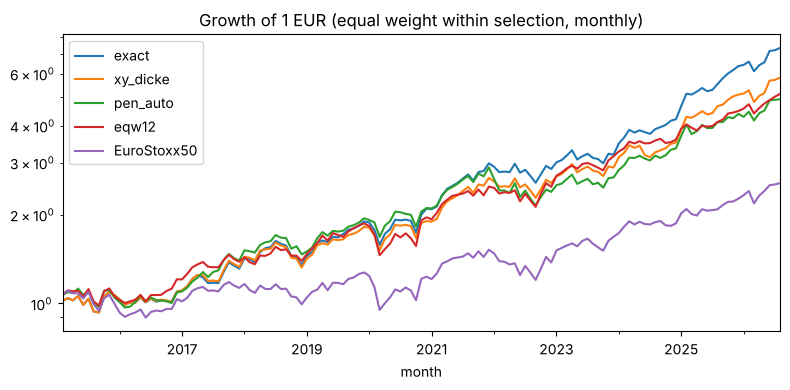

In [7]:
bm=pd.read_csv(f'{DATA}/benchmark_curvo.csv'); bm.columns=['d','v']
bm.index=pd.to_datetime(bm.d,format='%m/%Y')+pd.offsets.MonthEnd(0); bmr=bm.v.pct_change()
Rq=R[QAOA_TICKERS]; nxt={t:R.index[R.index>=t][0] for t in months}  # rebalance at end of month t-1, earn month t
def sel_ret(t,idx):
    if idx<0: return Rq.loc[t].mean()
    return Rq.loc[t].values[bits[idx]==1].mean()
pf=[]
for t in months:
    c=scaled_cost(inst[t][2]); opt=int(np.where(FEAS&(c<=1e-12))[0][0])
    g=lambda m: int(res[(res.month==t)&(res.method==m)].best_idx.iloc[0])
    pf.append(dict(month=t,exact=sel_ret(t,opt),xy_dicke=sel_ret(t,g('xy_dicke')),pen_auto=sel_ret(t,g('pen_auto')),
                   eqw12=Rq.loc[t].mean(),EuroStoxx50=bmr.get(t,np.nan)))
pf=pd.DataFrame(pf).set_index('month'); pf.to_csv(f'{OUT}/oos_returns.csv')
def stats(r):
    r=r.dropna(); cagr=(1+r).prod()**(12/len(r))-1; vol=r.std()*12**.5
    w=(1+r).cumprod(); dd=(w/w.cummax()-1).min()
    return pd.Series({'CAGR':cagr,'vol':vol,'Sharpe(rf=0)':cagr/vol,'maxDD':dd})
display(pf.apply(stats).T.round(3))
(1+pf).cumprod().plot(logy=True,figsize=(8,4),title='Growth of 1 EUR (equal weight within selection, monthly)'); plt.tight_layout(); plt.savefig(f'{OUT}/oos.png',dpi=130)
print('Check: Curvo vs eqw12 correlation', pf.EuroStoxx50.corr(pf.eqw12).round(2))

## 7. Figure: quality per method across months

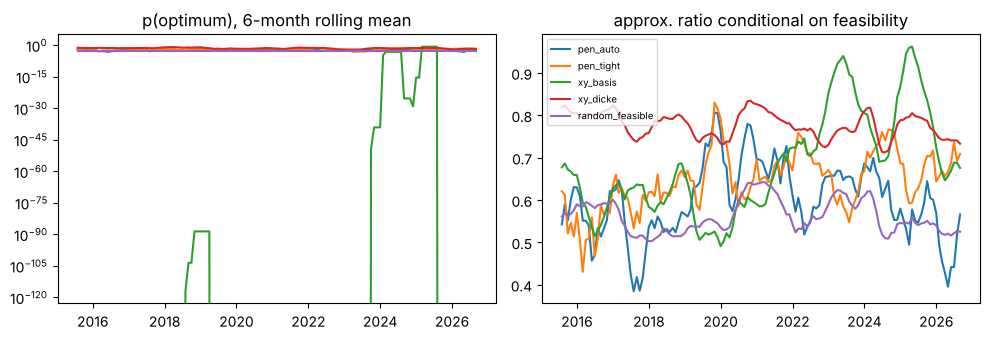

In [8]:
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
for m in METHODS+['random_feasible']:
    d=res[res.method==m].set_index('month')
    ax[0].plot(d.p_opt.rolling(6).mean(),label=m); ax[1].plot(d.ratio_cond.rolling(6).mean(),label=m)
ax[0].set_title('p(optimum), 6-month rolling mean'); ax[1].set_title('approx. ratio conditional on feasibility')
ax[0].set_yscale('log'); ax[1].legend(fontsize=7); plt.tight_layout(); plt.savefig(f'{OUT}/quality.png',dpi=130)

## 8. What this shows and what it does not
Read the numbers above; the conclusions below are printed from them by the next cell.
* Not shown: any quantum advantage (classical enumeration solves each month in milliseconds), hardware behaviour, or a tradeable strategy (survivorship bias, no costs, 12-month estimates of μ are mostly noise).
* Next: sector constraints (one XY ring per sector), mixed equity+commodity universe, larger n with non-exact simulation.

In [9]:
s=res[res.method.isin(METHODS)].groupby('method')[['p_opt','p_feas','ratio_cond']].mean()
best=s.p_opt.idxmax()
print(f"Highest mean p(optimum): {best} ({s.p_opt.max():.3f}); random feasible guess: {1/FEAS.sum():.4f}.")
print(f"Penalty feasibility: auto {s.loc['pen_auto','p_feas']:.3f}, tight {s.loc['pen_tight','p_feas']:.3f} (XY methods: 1 by construction).")
print(f"Transfer: one warm start reaches p_opt {tr.B_popt.mean():.3f} vs {tr.A_popt.mean():.3f} fresh, with {tr.B_nfev.mean()/tr.A_nfev.mean():.0%} of the evaluations.")
json.dump({'summary':s.round(4).to_dict()},open(f'{OUT}/summary.json','w'),indent=1)

Highest mean p(optimum): xy_dicke (0.035); random feasible guess: 0.0020.
Penalty feasibility: auto 0.552, tight 0.501 (XY methods: 1 by construction).
Transfer: one warm start reaches p_opt 0.035 vs 0.035 fresh, with 12% of the evaluations.


# Part 2 — Group constraints: sectors and a mixed equity + commodity universe
Both experiments use the same machinery: assets are split into groups and we need **exactly kᵍ assets from each group g**.
* Constraint-native: one XY ring per group (2-asset group → a single XY edge), starting from the product of per-group Dicke states = uniform superposition over all feasible portfolios. Every group's count is conserved exactly.
* Penalty: transverse mixer, |+⟩ⁿ, H = c + P·Σ_g (Σ_{i∈g} xᵢ − kᵍ)², with P = P_tight as in Part 1 (the best penalty variant there).
* Control: the Part 1 global XY-Dicke (only Σx = 4 enforced), to measure how often ignoring the group constraint breaks it.

**2a, sectors** (same 12 stocks): exactly 1 IT, 1 Industrials, 1 Financials and 1 from the other six sectors → 48 feasible portfolios.
**2b, mixed universe**: 8 stocks + 4 commodities (gold, platinum, copper, WTI, in EUR), exactly 3 stocks + 1 commodity → 224 feasible portfolios. The extreme WTI months flagged by the download log (2020-03, 2020-05, 2026-03) are kept as genuine market moves. Commodity futures are continuous front-month series, so roll effects are part of the returns. This is a known limitation.

In [10]:
com=pd.read_csv(f'{DATA}/commodities_monthly_eur.csv',index_col=0,parse_dates=True)
assert (com.index==px.index).all()
Lall=L.join(np.log(com).diff().dropna()); Rall=R.join(com.pct_change().dropna())
def ring_edges(idx):
    idx=list(idx)
    if len(idx)<2: return [],[]
    if len(idx)==2: return [(idx[0],idx[1])],[]
    e=[(idx[i],idx[(i+1)%len(idx)]) for i in range(len(idx))]; return e[0::2],e[1::2]
def setup(groups):  # groups: list of (index list, k_g)
    feas=np.ones(N,bool); E0=[];E1=[]
    for g,kg in groups:
        feas&=bits[:,g].sum(1)==kg; a,b=ring_edges(g); E0+=a; E1+=b
    viol=sum((bits[:,g].sum(1)-kg)**2 for g,kg in groups)
    return dict(feas=feas,layers=[pairs(E0),pairs(E1)],viol=viol,start=feas/np.sqrt(feas.sum())+0j)
def run_g(method,c,G,seed):
    rng=np.random.default_rng(seed)
    if method=='pen_tight_g':
        H=c+penalties(c)['pen_tight']*G['viol']; start=plus
        mix=apply_rx
    elif method=='xy_grouped':
        H=c; start=G['start']
        def mix(psi,beta,lay=G['layers']):
            cc,ss=np.cos(beta),-1j*np.sin(beta)
            for layer in lay:
                for i,j in layer:
                    a=psi[i].copy(); b=psi[j]; psi[i]=cc*a+ss*b; psi[j]=ss*a+cc*b
            return psi
    else:  # global xy_dicke, group constraint ignored
        H=c; start=dicke; mix=apply_xy
    def state(th):
        psi=start.copy()
        for l in range(P_LAYERS): psi=mix(psi*np.exp(-1j*th[l]*H),th[P_LAYERS+l])
        return psi
    E=lambda th: float(np.abs(state(th))**2@H)
    best=None; nf=0
    for _ in range(RESTARTS):
        x0=np.r_[rng.uniform(0,2*np.pi,P_LAYERS),rng.uniform(0,np.pi,P_LAYERS)]
        r=minimize(E,x0,method='L-BFGS-B',options={'maxiter':200}); nf+=r.nfev
        if best is None or r.fun<best.fun: best=r
    return np.abs(state(best.x))**2,nf
def gmetrics(pr,c,feas):
    pf=pr[feas].sum(); opt=feas&(c<=1e-12)
    return dict(p_feas=pf,p_opt=pr[opt].sum(),ratio_cond=1-(pr[feas]@c[feas])/pf if pf>1e-12 else np.nan)
def experiment(tickers,groups,Lsrc,Rsrc,tag):
    G=setup(groups); feas=G['feas']; out=[]; port=[]
    for mi,t in enumerate(months):
        h=Lsrc.loc[Lsrc.index<t,tickers].iloc[-WIN:]; mu=h.mean().values*12; S=h.cov().values*12
        f=bits@mu-Q_RISK*np.einsum('si,ij,sj->s',bits,S,bits)
        fe=f[feas]; c=(fe.max()-f)/(fe.max()-fe.min())
        rec={'month':t,'exact':Rsrc.loc[t,tickers].values[bits[np.where(feas&(c<=1e-12))[0][0]]==1].mean()}
        for m in ['pen_tight_g','xy_grouped','xy_dicke_global']:
            pr,nf=run_g(m,c,G,SEED+mi)
            rs=np.random.default_rng(SEED+7*mi).choice(N,SHOTS,p=pr/pr.sum()); ok=rs[feas[rs]]
            b=ok[np.argmin(c[ok])] if len(ok) else -1
            out.append(dict(month=t,method=m,nfev=nf,best_shot_opt=float(b>=0 and c[b]<=1e-12),**gmetrics(pr,c,feas)))
            rec[m]=Rsrc.loc[t,tickers].values[bits[b]==1].mean() if b>=0 else Rsrc.loc[t,tickers].mean()
        out.append(dict(month=t,method='random_feasible',ratio_cond=1-c[feas].mean(),p_opt=1/feas.sum(),p_feas=feas.mean()))
        port.append(rec)
    d=pd.DataFrame(out); d.to_csv(f'{OUT}/{tag}_monthly.csv',index=False)
    tab=[]
    for m in ['pen_tight_g','xy_grouped','xy_dicke_global','random_feasible']:
        x=d[d.method==m]; row={'method':m}
        for k_ in ['ratio_cond','p_opt','p_feas']:
            mu_,lo,hi=boot(x[k_]); row[k_]=f'{mu_:.3f} [{lo:.3f}, {hi:.3f}]'
        if m!='random_feasible': row['best_of_100_finds_opt']=f"{x.best_shot_opt.mean():.2f}"; row['mean_nfev']=int(x.nfev.mean())
        tab.append(row)
    tab=pd.DataFrame(tab).set_index('method'); tab.to_csv(f'{OUT}/{tag}_summary.csv'); display(tab)
    pv=d.pivot(index='month',columns='method',values='p_opt'); dd=pv.xy_grouped-pv.pen_tight_g
    print(f'{tag}: p_opt xy_grouped - pen_tight_g = {dd.mean():+.3f}, Wilcoxon p={wilcoxon(dd).pvalue:.1e}, grouped better in {(dd>0).mean():.0%} of months; feasible states {feas.sum()}')
    port=pd.DataFrame(port).set_index('month'); port['EuroStoxx50']=bmr.reindex(port.index).values
    display(port.apply(stats).T.round(3)); port.to_csv(f'{OUT}/{tag}_oos_returns.csv')
    return d,port

## 2a. Sector constraints

In [11]:
sec=uni.loc[QAOA_TICKERS,'sector'].values
gi=lambda s: [i for i,x in enumerate(sec) if x==s]
big=['Information Technology','Industrials','Financials']
groups_sec=[(gi(s),1) for s in big]+[([i for i,x in enumerate(sec) if x not in big],1)]
print([[QAOA_TICKERS[i] for i in g] for g,_ in groups_sec])
t0=time.time(); sec_res,sec_port=experiment(QAOA_TICKERS,groups_sec,L,R,'sector'); print(f'{time.time()-t0:.0f}s')

[['ASML.AS', 'SAP.DE'], ['SIE.DE', 'AIR.PA'], ['SAN.MC', 'ALV.DE'], ['TTE.PA', 'IBE.MC', 'MC.PA', 'OR.PA', 'SAN.PA', 'DTE.DE']]


,ratio_cond,p_opt,p_feas,best_of_100_finds_opt,mean_nfev
method,,,,,
pen_tight_g,"0.593 [0.567, 0.619]","0.009 [0.007, 0.012]","0.169 [0.143, 0.196]",0.45,656.0
xy_grouped,"0.899 [0.892, 0.906]","0.262 [0.238, 0.287]","1.000 [1.000, 1.000]",1.00,840.0
xy_dicke_global,"0.811 [0.797, 0.824]","0.024 [0.020, 0.029]","0.113 [0.104, 0.121]",0.73,850.0
random_feasible,"0.524 [0.516, 0.533]","0.021 [0.021, 0.021]","0.012 [0.012, 0.012]",NaN,NaN


sector: p_opt xy_grouped - pen_tight_g = +0.252, Wilcoxon p=1.5e-24, grouped better in 100% of months; feasible states 48


,CAGR,vol,Sharpe(rf=0),maxDD
exact,0.201,0.181,1.109,-0.193
pen_tight_g,0.203,0.184,1.106,-0.245
xy_grouped,0.201,0.181,1.109,-0.193
xy_dicke_global,0.193,0.188,1.028,-0.252
EuroStoxx50,0.084,0.163,0.519,-0.253


228s


## 2b. Mixed equity + commodity universe

In [12]:
MIX=['ASML.AS','SIE.DE','SAN.MC','ALV.DE','TTE.PA','IBE.MC','MC.PA','SAN.PA','GC=F','PL=F','HG=F','CL=F']
groups_mix=[(list(range(8)),3),(list(range(8,12)),1)]
t0=time.time(); mix_res,mix_port=experiment(MIX,groups_mix,Lall,Rall,'mixed'); print(f'{time.time()-t0:.0f}s')

sel=[]
for t in months:
    h=Lall.loc[Lall.index<t,MIX].iloc[-WIN:]; mu=h.mean().values*12; S=h.cov().values*12
    G=setup(groups_mix); f=bits@mu-Q_RISK*np.einsum('si,ij,sj->s',bits,S,bits); f[~G['feas']]=-np.inf
    sel.append(MIX[8+int(np.argmax(bits[np.argmax(f)][8:]))])
print('commodity chosen by the exact optimum (share of months):'); print(pd.Series(sel).value_counts(normalize=True).round(2))

,ratio_cond,p_opt,p_feas,best_of_100_finds_opt,mean_nfev
method,,,,,
pen_tight_g,"0.661 [0.637, 0.684]","0.012 [0.009, 0.017]","0.342 [0.326, 0.359]",0.47,706.0
xy_grouped,"0.816 [0.809, 0.822]","0.082 [0.071, 0.093]","1.000 [1.000, 1.000]",0.91,873.0
xy_dicke_global,"0.793 [0.786, 0.801]","0.033 [0.028, 0.037]","0.481 [0.470, 0.493]",0.78,869.0
random_feasible,"0.557 [0.547, 0.568]","0.004 [0.004, 0.004]","0.055 [0.055, 0.055]",NaN,NaN


mixed: p_opt xy_grouped - pen_tight_g = +0.070, Wilcoxon p=7.4e-22, grouped better in 92% of months; feasible states 224


,CAGR,vol,Sharpe(rf=0),maxDD
exact,0.131,0.130,1.004,-0.181
pen_tight_g,0.148,0.135,1.093,-0.179
xy_grouped,0.133,0.130,1.021,-0.181
xy_dicke_global,0.128,0.129,0.996,-0.181
EuroStoxx50,0.084,0.163,0.519,-0.253


243s


commodity chosen by the exact optimum (share of months):
GC=F    0.60
HG=F    0.21
CL=F    0.14
PL=F    0.05
Name: proportion, dtype: float64


## Part 2: reading the results
* The question is whether the Part 1 finding (constraint-native > penalty) survives when there are several constraints at once. Penalty QAOA now has to satisfy four (2a) or two (2b) equalities simultaneously with one transverse mixer.
* The global-Dicke control shows the price of encoding only part of the constraint. Its `p_feas` is the share of probability that lands in portfolios breaking the sector or asset-class rule.
* Out-of-sample numbers are again descriptive (survivorship bias, no costs; commodities are front-month futures with roll effects).

In [13]:
for tag,d in [('sector',sec_res),('mixed',mix_res)]:
    s=d[d.method!='random_feasible'].groupby('method')[['p_opt','p_feas']].mean()
    print(f"{tag}: p_opt grouped {s.loc['xy_grouped','p_opt']:.3f} vs penalty {s.loc['pen_tight_g','p_opt']:.3f}; penalty p_feas {s.loc['pen_tight_g','p_feas']:.3f}; global-Dicke p_feas {s.loc['xy_dicke_global','p_feas']:.3f}")

sector: p_opt grouped 0.262 vs penalty 0.009; penalty p_feas 0.169; global-Dicke p_feas 0.113
mixed: p_opt grouped 0.082 vs penalty 0.012; penalty p_feas 0.342; global-Dicke p_feas 0.481
